In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
def simulate_gbm(S0, mu, sigma, T, steps):
    
    prices = [S0]

    dt = T / steps

    for step in range(steps):
        drift = (mu - sigma**2 /2) * dt
        random = sigma * np.random.normal(0, 1) * np.sqrt(dt)
        next_price = prices[-1] * np.exp(drift + random)
        prices.append(next_price)

    return prices

In [17]:

eurusd = simulate_gbm(S0=1.1000, mu=0.01, sigma=0.01, T=1, steps=252)
audusd = simulate_gbm(S0=0.6700, mu=0.01, sigma=0.01, T=1, steps=252)
euraud = [e / a for e, a in zip(eurusd, audusd)]

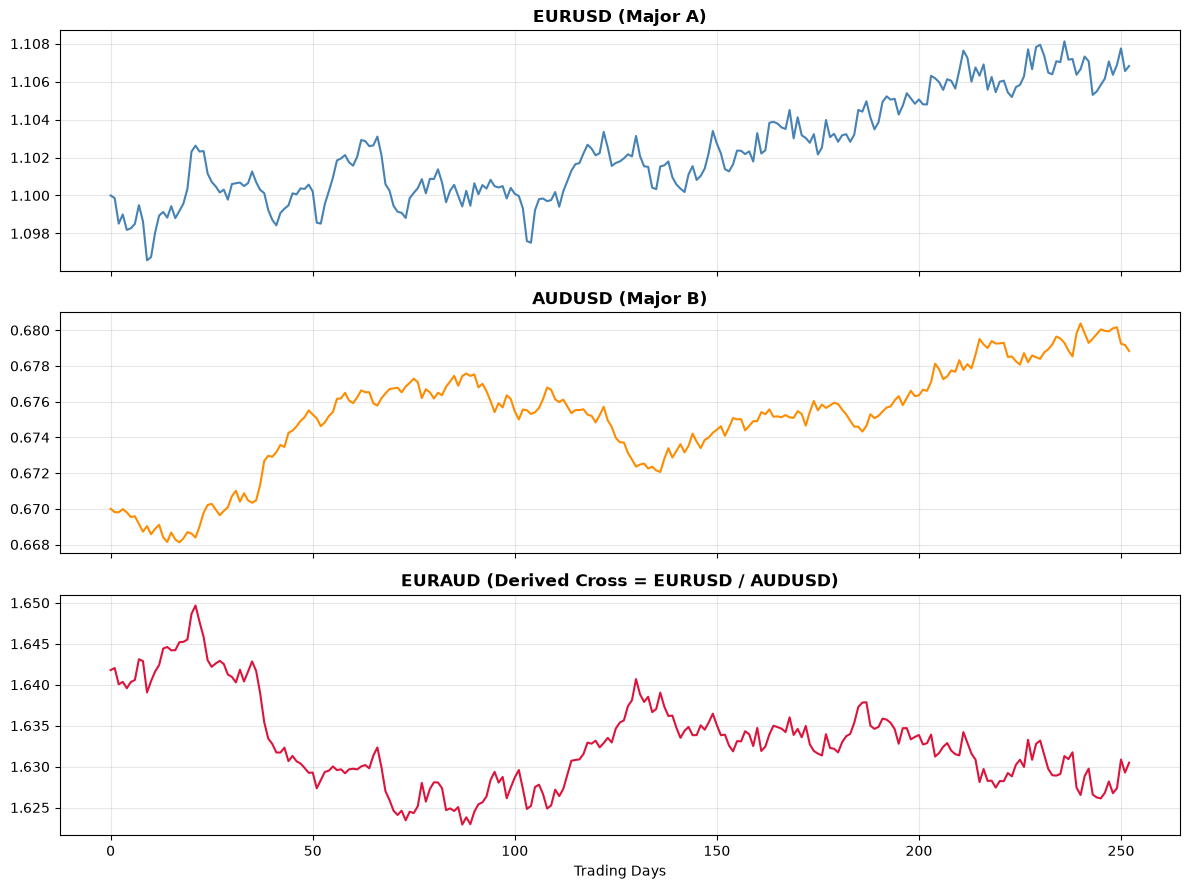

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(eurusd, color='steelblue', linewidth=1.5)
axes[0].set_title('EURUSD (Major A)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

axes[1].plot(audusd, color='darkorange', linewidth=1.5)
axes[1].set_title('AUDUSD (Major B)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

axes[2].plot(euraud, color='crimson', linewidth=1.5)
axes[2].set_title('EURAUD (Derived Cross = EURUSD / AUDUSD)', fontsize=12, fontweight='bold')
axes[2].grid(True, alpha=0.3)
axes[2].set_xlabel('Trading Days')

plt.tight_layout()
plt.show()